# Étape 1 — Exploration des données (EDA)

**Objectif** : comprendre la structure et les biais du dataset *avant* de modéliser, pour fonder les décisions de :
- nettoyage (NaN),
- split train/validation (stratifié ou non),
- échantillonnage pendant le training (weighted sampler ou non),
- loss (pondérée selon la métrique),
- stratégie d'équité (gap homme/femme).

**Rappel de la métrique** :
$$ Err = \frac{\sum_i w_i(p_i - GT_i)^2}{\sum_i w_i}, \quad w_i = \frac{1}{30} + GT_i $$
$$ Score = \frac{Err_F + Err_M}{2} + |Err_F - Err_M| $$

Les visages **fortement occultés** pèsent jusqu'à 31× plus qu'un visage non occulté.  
Convention du dataset : `gender = 1.0` → homme, `gender = 0.0` → femme.

## 0. Imports et chemins

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

DATA_DIR = Path('data')
IMAGE_DIR = Path('crops/Crop_224_5fp_100K')

TRAIN_CSV = DATA_DIR / 'train.csv'
TEST_CSV  = DATA_DIR / 'test_students.csv'

print('Train CSV exists :', TRAIN_CSV.exists())
print('Test  CSV exists :', TEST_CSV.exists())
print('Image dir exists :', IMAGE_DIR.exists())

Train CSV exists : True
Test  CSV exists : True
Image dir exists : True


## 1. Inspection brute des CSV

On regarde **avant tout nettoyage** : nombre de lignes, colonnes, types, premières lignes.  
Pourquoi : si on fait `dropna()` tout de suite (comme la baseline), on a déjà perdu de l'info sans le savoir.

In [2]:
df_train_raw = pd.read_csv(TRAIN_CSV)
df_test_raw  = pd.read_csv(TEST_CSV)

print(f'Train: {len(df_train_raw):,} lignes, colonnes = {list(df_train_raw.columns)}')
print(f'Test : {len(df_test_raw):,} lignes, colonnes = {list(df_test_raw.columns)}')
print()
print('--- dtypes train ---')
print(df_train_raw.dtypes)
print('--- dtypes test ---')
print(df_test_raw.dtypes)

Train: 100,000 lignes, colonnes = ['filename', 'FaceOcclusion', 'gender']
Test : 29,980 lignes, colonnes = ['filename']

--- dtypes train ---
filename             str
FaceOcclusion    float64
gender           float64
dtype: object
--- dtypes test ---
filename    str
dtype: object


In [3]:
df_train_raw.head()

,filename,FaceOcclusion,gender
0,database3/database3/m.01w0zk1/66-FaceId-0_alig...,0.024005,1.0
1,database3/database3/m.016ywr/88-FaceId-0_align...,0.030028,1.0
2,database3/database3/m.02dfmb/105-FaceId-0_alig...,0.009984,0.0
3,database3/database3/m.01_h_s/33-FaceId-5_align...,0.255016,1.0
4,database3/database3/m.02lqkv/85-FaceId-0_align...,0.252091,1.0


In [4]:
df_test_raw.head()

,filename
0,database3/database3/m.0256vn/81-FaceId-0_align...
1,database3/database3/m.01dgwg/29-FaceId-0_align...
2,database3/database3/m.02l0nk/72-FaceId-0_align...
3,database3/database3/m.026jp3/94-FaceId-1_align...
4,database3/database3/m.01ncgyv/24-FaceId-0_alig...


## 2. Analyse des valeurs manquantes (NaN)

In [5]:
def nan_report(df, name):
    print(f'=== {name} ({len(df):,} lignes) ===')
    n_nan = df.isna().sum()
    pct = (n_nan / len(df) * 100).round(3)
    report = pd.DataFrame({'n_nan': n_nan, 'pct_nan': pct})
    print(report)
    n_after_drop = len(df.dropna())
    print(f'Après dropna() global : {n_after_drop:,} lignes ({100*n_after_drop/len(df):.2f}% conservés)')
    print()

nan_report(df_train_raw, 'TRAIN')
nan_report(df_test_raw,  'TEST')

=== TRAIN (100,000 lignes) ===
               n_nan  pct_nan
filename           0      0.0
FaceOcclusion      0      0.0
gender             0      0.0
Après dropna() global : 100,000 lignes (100.00% conservés)

=== TEST (29,980 lignes) ===
          n_nan  pct_nan
filename      0      0.0
Après dropna() global : 29,980 lignes (100.00% conservés)



In [6]:
# Analyse fine train : les NaN de 'gender' sont-ils concentrés sur certaines occlusions ?
# (Si gender NaN ↔ forte occlusion, alors dropna() biaiserait la val set vers les faibles occlusions.)
if df_train_raw['gender'].isna().any():
    mask_g_nan = df_train_raw['gender'].isna()
    print("Stats de FaceOcclusion pour gender NaN vs non-NaN :")
    print(df_train_raw.groupby(mask_g_nan)['FaceOcclusion'].describe())
else:
    print("Aucun NaN sur 'gender' en train.")

if df_train_raw['FaceOcclusion'].isna().any():
    mask_o_nan = df_train_raw['FaceOcclusion'].isna()
    print("\nGenre des lignes où FaceOcclusion est NaN :")
    print(df_train_raw.loc[mask_o_nan, 'gender'].value_counts(dropna=False))
else:
    print("\nAucun NaN sur 'FaceOcclusion' en train.")

Aucun NaN sur 'gender' en train.

Aucun NaN sur 'FaceOcclusion' en train.


## 3. Distribution de la cible `FaceOcclusion`

In [7]:
df_train = df_train_raw.dropna(subset=['FaceOcclusion']).copy()
print(df_train['FaceOcclusion'].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

count    100000.000000
mean          0.082720
std           0.086538
min           0.000000
10%           0.005453
25%           0.017928
50%           0.049661
75%           0.122675
90%           0.213300
95%           0.270883
99%           0.353890
max           1.000000
Name: FaceOcclusion, dtype: float64


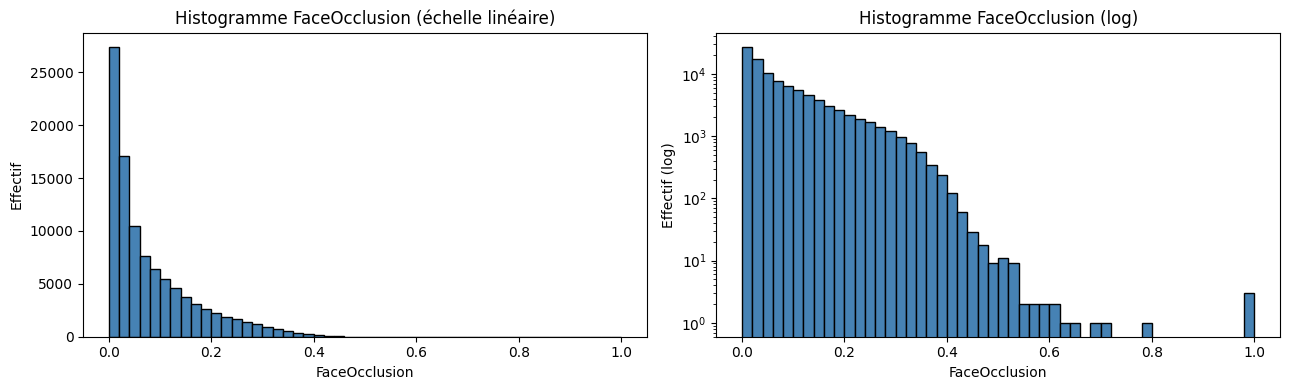

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df_train['FaceOcclusion'], bins=50, color='steelblue', edgecolor='black')
axes[0].set_title('Histogramme FaceOcclusion (échelle linéaire)')
axes[0].set_xlabel('FaceOcclusion'); axes[0].set_ylabel('Effectif')

axes[1].hist(df_train['FaceOcclusion'], bins=50, color='steelblue', edgecolor='black')
axes[1].set_yscale('log')
axes[1].set_title('Histogramme FaceOcclusion (log)')
axes[1].set_xlabel('FaceOcclusion'); axes[1].set_ylabel('Effectif (log)')
plt.tight_layout(); plt.show()

In [9]:
# Buckets d'occlusion + contribution au gradient vs à la métrique pondérée
bins   = [0.0, 0.05, 0.10, 0.20, 0.30, 0.50, 0.70, 1.01]
labels = ['0-5%', '5-10%', '10-20%', '20-30%', '30-50%', '50-70%', '70-100%']
df_train['occ_bin'] = pd.cut(df_train['FaceOcclusion'], bins=bins, labels=labels, include_lowest=True)

tbl = df_train.groupby('occ_bin', observed=True).agg(
    n=('FaceOcclusion', 'size'),
    mean_occ=('FaceOcclusion', 'mean'),
)
tbl['pct_samples'] = (tbl['n'] / tbl['n'].sum() * 100).round(2)
tbl['w_mean'] = 1/30 + tbl['mean_occ']
tbl['total_weight'] = tbl['n'] * tbl['w_mean']
tbl['pct_weight'] = (tbl['total_weight'] / tbl['total_weight'].sum() * 100).round(2)
tbl[['n', 'pct_samples', 'mean_occ', 'w_mean', 'pct_weight']]

,n,pct_samples,mean_occ,w_mean,pct_weight
occ_bin,,,,,
0-5%,50166,50.17,0.019781,0.053115,22.96
5-10%,18763,18.76,0.072811,0.106145,17.16
10-20%,19558,19.56,0.142356,0.175689,29.61
20-30%,8372,8.37,0.243919,0.277252,20.00
30-50%,3105,3.10,0.343249,0.376583,10.08
50-70%,31,0.03,0.547121,0.580454,0.16
70-100%,5,0.00,0.895162,0.928496,0.04


## 4. Distribution du genre et distribution jointe `gender × occlusion`

On vérifie :
1. l'équilibre H/F (s'il est très déséquilibré, le modèle apprendra mieux le genre majoritaire),
2. si les distributions d'occlusion diffèrent entre H et F (un décalage systématique aide à comprendre d'où vient le gap d'équité).

In [10]:
df_lab = df_train.dropna(subset=['gender']).copy()
df_lab['gender_str'] = df_lab['gender'].map({0.0: 'Female', 1.0: 'Male'})
print(df_lab['gender_str'].value_counts())
print()
print('Stats FaceOcclusion par genre :')
print(df_lab.groupby('gender_str')['FaceOcclusion'].describe(percentiles=[0.5, 0.9, 0.99]))

gender_str
Male      67600
Female    32400
Name: count, dtype: int64

Stats FaceOcclusion par genre :
              count      mean       std  min       50%       90%       99%       max
gender_str                                                                          
Female      32400.0  0.128531  0.093857  0.0  0.108855  0.271810  0.383726  0.987781
Male        67600.0  0.060763  0.073267  0.0  0.031471  0.168475  0.317720  1.000000


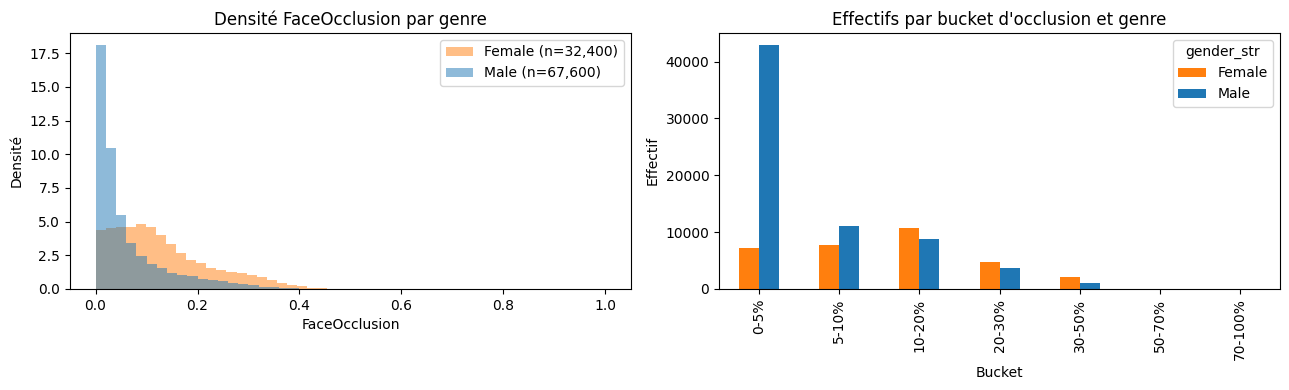


Table croisée (proportions par genre):
gender_str  Female   Male
occ_bin                  
0-5%         22.35  63.50
5-10%        23.59  16.45
10-20%       33.04  13.10
20-30%       14.40   5.48
30-50%        6.58   1.44
50-70%        0.04   0.03
70-100%       0.00   0.01


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histogrammes superposés normalisés (densité) pour comparer les formes
for g, color in [('Female', 'tab:orange'), ('Male', 'tab:blue')]:
    vals = df_lab.loc[df_lab['gender_str'] == g, 'FaceOcclusion']
    axes[0].hist(vals, bins=50, alpha=0.5, label=f'{g} (n={len(vals):,})', color=color, density=True)
axes[0].set_title('Densité FaceOcclusion par genre')
axes[0].set_xlabel('FaceOcclusion'); axes[0].set_ylabel('Densité')
axes[0].legend()

# Effectifs par bucket × genre
ct = pd.crosstab(df_lab['occ_bin'], df_lab['gender_str'])
ct.plot(kind='bar', ax=axes[1], color=['tab:orange', 'tab:blue'])
axes[1].set_title('Effectifs par bucket d\'occlusion et genre')
axes[1].set_xlabel('Bucket'); axes[1].set_ylabel('Effectif')
plt.tight_layout(); plt.show()

print('\nTable croisée (proportions par genre):')
print((ct.div(ct.sum(axis=0), axis=1) * 100).round(2))

## 5. Vérification des fichiers images

On vérifie qu'un échantillon est lisible et qu'aucune ligne CSV ne pointe vers un fichier manquant.  

In [12]:
rng = np.random.default_rng(42)
sample = df_train.sample(n=min(2000, len(df_train)), random_state=42)
missing = []
for fn in sample['filename']:
    if not (IMAGE_DIR / fn).exists():
        missing.append(fn)
print(f'Sur {len(sample)} fichiers échantillonnés, {len(missing)} manquants.')
if missing[:5]:
    print('Exemples :', missing[:5])

Sur 2000 fichiers échantillonnés, 5 manquants.
Exemples : ['database2/database2/test/482.webp', 'database2/database2/train/236.webp', 'database2/database2/train/423.webp', 'database2/database2/train/488.webp', 'database2/database2/train/164.webp']


Mode : RGB | Taille : (224, 224) | Format : WEBP
FaceOcclusion : 0.024005 | gender : 1.0


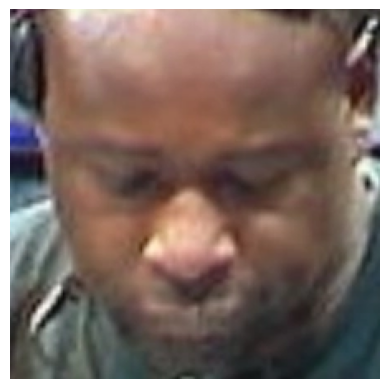

In [ ]:
row = df_train.iloc[0]
img = Image.open(IMAGE_DIR / row['filename'])
print('Mode :', img.mode, '| Taille :', img.size, '| Format :', img.format)
print('FaceOcclusion :', row['FaceOcclusion'], '| gender :', row['gender'])
plt.imshow(img); plt.axis('off'); plt.show()

## 6. Visualisation par bucket d'occlusion

Voir ce que le modèle doit apprendre. Pour chaque bucket, on affiche quelques exemples H et F.

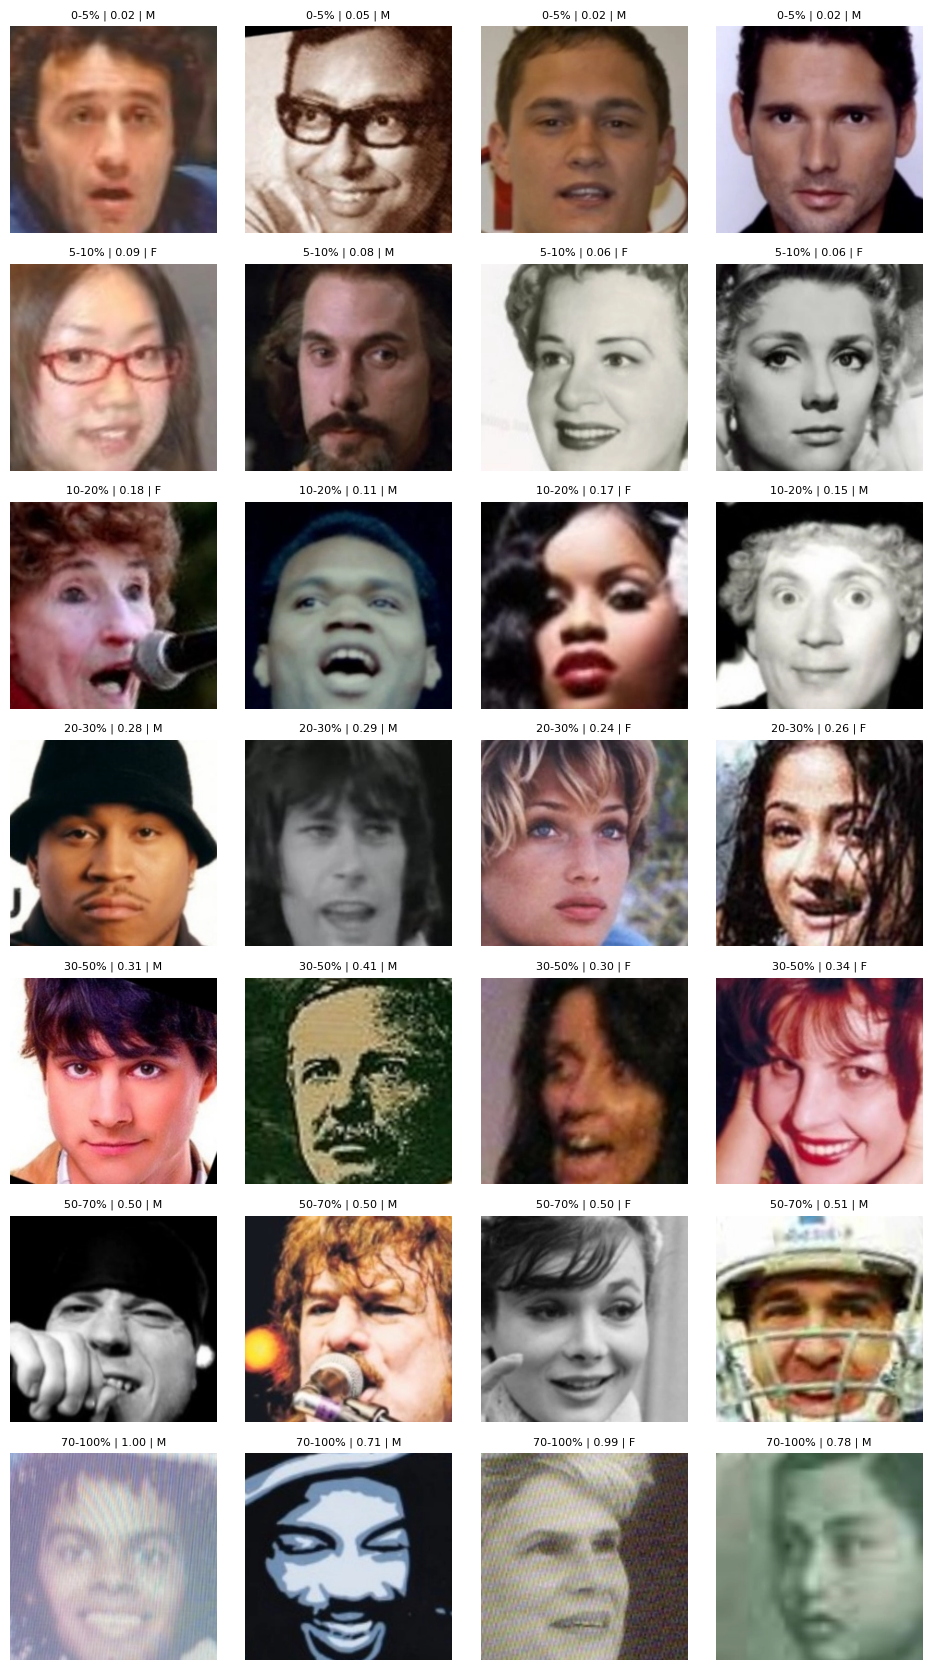

In [14]:
def show_grid_by_bucket(df, n_per_bucket=4, seed=0):
    buckets = labels  # défini plus haut
    fig, axes = plt.subplots(len(buckets), n_per_bucket, figsize=(2.4*n_per_bucket, 2.4*len(buckets)))
    for i, b in enumerate(buckets):
        sub = df[df['occ_bin'] == b]
        if len(sub) == 0:
            for j in range(n_per_bucket):
                axes[i, j].axis('off')
            continue
        picks = sub.sample(n=min(n_per_bucket, len(sub)), random_state=seed)
        for j, (_, row) in enumerate(picks.iterrows()):
            try:
                img = Image.open(IMAGE_DIR / row['filename'])
                axes[i, j].imshow(img)
            except Exception as e:
                axes[i, j].text(0.5, 0.5, 'erreur', ha='center')
            g = {0.0: 'F', 1.0: 'M'}.get(row.get('gender'), '?')
            axes[i, j].set_title(f'{b} | {row["FaceOcclusion"]:.2f} | {g}', fontsize=8)
            axes[i, j].axis('off')
    plt.tight_layout(); plt.show()

show_grid_by_bucket(df_lab, n_per_bucket=4, seed=1)

## 7. Identités : risque de fuite dans le split

Les noms de fichier contiennent une identité (`m.01w0zk1`, etc.). Si la **même identité** apparaît à la fois en train et en val, on **surestime** la performance (le modèle reconnaît la personne, pas l'occlusion).  
On vérifie le nombre d'identités et si plusieurs images partagent la même.

In [15]:
def extract_identity(path):
    """Extraction d'identité robuste, dépendant de la sous-base.

    - database3/database3/m.XXX/...    -> 'db3:m.XXX'  (vraie identité MID Freebase)
    - database1/imgXXXXX.webp          -> 'db1:imgXXXXX' (1 image = 1 sample, pas d'ID partagée)
    - database2/database2/sub/N.webp   -> 'db2:sub/N'  (volume négligeable)
    """
    parts = path.split('/')
    if not parts:
        return 'unk'
    if parts[0] == 'database3' and len(parts) >= 3:
        return 'db3:' + parts[2]
    if parts[0] == 'database1' and len(parts) >= 2:
        return 'db1:' + parts[1]
    if parts[0] == 'database2' and len(parts) >= 4:
        return 'db2:' + parts[2] + '/' + parts[3]
    return 'unk:' + path

df_train['db'] = df_train['filename'].str.split('/').str[0]
df_test_raw['db'] = df_test_raw['filename'].str.split('/').str[0]
df_train['identity'] = df_train['filename'].map(extract_identity)
df_test_raw['identity'] = df_test_raw['filename'].map(extract_identity)

print('=== Sous-bases (train) ===')
print(df_train['db'].value_counts())
print('\n=== Sous-bases (test) ===')
print(df_test_raw['db'].value_counts())

print(f"\nTrain : {len(df_train):,} images, {df_train['identity'].nunique():,} identités uniques")
print(f"Test  : {len(df_test_raw):,} images, {df_test_raw['identity'].nunique():,} identités uniques")

# Distribution images/identité, restreinte à database3 (la seule où l'ID est significative)
db3 = df_train[df_train['db'] == 'database3']
print(f"\n--- database3 uniquement ({len(db3):,} images, {db3['identity'].nunique():,} identités) ---")
print('Images par identité :')
print(db3['identity'].value_counts().describe())

# Overlap réel train/test sur les identités (db3 seulement)
db3_test = df_test_raw[df_test_raw['db'] == 'database3']
shared = set(db3['identity']) & set(db3_test['identity'])
print(f"\nIdentités db3 partagées train/test : {len(shared):,} "
      f"({100*len(shared)/db3['identity'].nunique():.1f}% des identités train db3)")

=== Sous-bases (train) ===
db
database3    96023
database1     3747
database2      230
Name: count, dtype: int64

=== Sous-bases (test) ===
db
database3    28435
database1     1427
database2      118
Name: count, dtype: int64

Train : 100,000 images, 19,842 identités uniques
Test  : 29,980 images, 12,340 identités uniques

--- database3 uniquement (96,023 images, 15,865 identités) ---
Images par identité :
count    15865.000000
mean         6.052506
std          3.925325
min          1.000000
25%          3.000000
50%          5.000000
75%          9.000000
max         29.000000
Name: count, dtype: float64

Identités db3 partagées train/test : 10,497 (66.2% des identités train db3)
